In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("donnees_preparees.csv")

X = df.drop(columns='Machine failure')
y = df['Machine failure']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(8000, 9) (2000, 9)


In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

[[1862   10]
 [  32   96]]
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1872
           1       0.91      0.75      0.82       128

    accuracy                           0.98      2000
   macro avg       0.94      0.87      0.90      2000
weighted avg       0.98      0.98      0.98      2000



In [3]:
#compromis recall/precision
# agissons sur le seuil
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

proba = rf.predict_proba(X_test)[:, 1]

for seuil in [0.2, 0.3, 0.4, 0.5]:
    y_pred_seuil = (proba >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_seuil).ravel()
    print(f"Seuil {seuil} | precision={precision_score(y_test, y_pred_seuil):.2f} "
          f"| recall={recall_score(y_test, y_pred_seuil):.2f} "
          f"| f1={f1_score(y_test, y_pred_seuil):.2f} "
          f"| fausses alertes={fp} | pannes ratées={fn}")

Seuil 0.2 | precision=0.49 | recall=0.81 | f1=0.61 | fausses alertes=107 | pannes ratées=24
Seuil 0.3 | precision=0.67 | recall=0.77 | f1=0.72 | fausses alertes=48 | pannes ratées=30
Seuil 0.4 | precision=0.82 | recall=0.77 | f1=0.79 | fausses alertes=22 | pannes ratées=30
Seuil 0.5 | precision=0.91 | recall=0.75 | f1=0.82 | fausses alertes=10 | pannes ratées=32


In [4]:
# 24 pannes que le modele ne detecte pas meme au seuil de 0.2
orig = pd.read_csv("ai4i_predictive_maintenance.csv")

masque = (proba < 0.2) & (y_test.values == 1)
indices = X_test.index[masque]

orig.loc[indices, ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum()

TWF    22
HDF     0
PWF     0
OSF     1
RNF     1
dtype: int64

In [5]:
twf = orig[orig['TWF'] == 1]['Tool wear [min]']
print(twf.describe())

zone = orig[(orig['Tool wear [min]'] >= 200) & (orig['Tool wear [min]'] <= 240)]
print(len(zone), zone['TWF'].sum(), zone['TWF'].mean())

count    154.000000
mean     224.396104
std       14.231246
min      200.000000
25%      212.000000
50%      224.000000
75%      236.000000
max      249.000000
Name: Tool wear [min], dtype: float64
1589 133 0.08370044052863436


### La majorité des pannes non détectées sont des pannes d’usure d’outil (TWF). Dans la zone d’usure critique (200 à 240 min), seulement 8,4 % des outils tombent en panne : ce phénomène est essentiellement aléatoire avec les capteurs disponibles, et constitue une limite de l’information, pas du modèle.

In [6]:
# essayons avec XGBOOST
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [7]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Noms de colonnes compatibles avec XGBoost (pas de crochets)
renommer = lambda c: c.replace('[', '(').replace(']', ')')
X_train_xgb = X_train.rename(columns=renommer)
X_test_xgb = X_test.rename(columns=renommer)

# Poids des pannes (rares) par rapport aux machines saines
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(ratio)

xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    scale_pos_weight=ratio,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train_xgb, y_train)

y_pred_xgb = xgb.predict(X_test_xgb)

print(confusion_matrix(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

14.686274509803921
[[1842   30]
 [  30   98]]
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1872
           1       0.77      0.77      0.77       128

    accuracy                           0.97      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.97      0.97      0.97      2000



 # validation croisee

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

modeles = {
    'Baseline (LogReg)': make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight='balanced', max_iter=1000)
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42
    ),
    'XGBoost': XGBClassifier(
        n_estimators=200, learning_rate=0.1, max_depth=4,
        scale_pos_weight=ratio, random_state=42, eval_metric='logloss'
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nom, modele in modeles.items():
    res = cross_validate(modele, X_train_xgb, y_train, cv=cv,
                         scoring=['precision', 'recall', 'f1'])
    print(f"{nom:18s} | precision={res['test_precision'].mean():.2f} ± {res['test_precision'].std():.2f} "
          f"| recall={res['test_recall'].mean():.2f} ± {res['test_recall'].std():.2f} "
          f"| f1={res['test_f1'].mean():.2f} ± {res['test_f1'].std():.2f}")

Baseline (LogReg)  | precision=0.23 ± 0.00 | recall=0.81 ± 0.03 | f1=0.36 ± 0.00
Random Forest      | precision=0.92 ± 0.04 | recall=0.80 ± 0.04 | f1=0.86 ± 0.04
XGBoost            | precision=0.79 ± 0.05 | recall=0.82 ± 0.04 | f1=0.80 ± 0.03


# on gardera le RANDOM FOREST

In [9]:
# choix du meilleur seuil
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

rf_cv = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)

proba_cv = cross_val_predict(rf_cv, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

for seuil in np.arange(0.2, 0.65, 0.05):
    pred = (proba_cv >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    print(f"Seuil {seuil:.2f} | precision={precision_score(y_train, pred):.2f} "
          f"| recall={recall_score(y_train, pred):.2f} "
          f"| f1={f1_score(y_train, pred):.2f} "
          f"| fausses alertes={fp} | pannes ratées={fn}")

Seuil 0.20 | precision=0.54 | recall=0.87 | f1=0.67 | fausses alertes=377 | pannes ratées=67
Seuil 0.25 | precision=0.63 | recall=0.85 | f1=0.72 | fausses alertes=259 | pannes ratées=77
Seuil 0.30 | precision=0.72 | recall=0.83 | f1=0.77 | fausses alertes=166 | pannes ratées=86
Seuil 0.35 | precision=0.79 | recall=0.82 | f1=0.81 | fausses alertes=109 | pannes ratées=90
Seuil 0.40 | precision=0.85 | recall=0.82 | f1=0.83 | fausses alertes=72 | pannes ratées=93
Seuil 0.45 | precision=0.89 | recall=0.81 | f1=0.85 | fausses alertes=49 | pannes ratées=98
Seuil 0.50 | precision=0.92 | recall=0.80 | f1=0.86 | fausses alertes=36 | pannes ratées=101
Seuil 0.55 | precision=0.94 | recall=0.79 | f1=0.86 | fausses alertes=26 | pannes ratées=106
Seuil 0.60 | precision=0.95 | recall=0.79 | f1=0.86 | fausses alertes=20 | pannes ratées=107


### on garde un seuil fixe a 0.45

## evaluation


In [10]:
rf_final = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf_final.fit(X_train, y_train)

proba_test = rf_final.predict_proba(X_test)[:, 1]
y_pred_final = (proba_test >= 0.45).astype(int)

print(confusion_matrix(y_test, y_pred_final))
print(classification_report(y_test, y_pred_final))

[[1857   15]
 [  31   97]]
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1872
           1       0.87      0.76      0.81       128

    accuracy                           0.98      2000
   macro avg       0.92      0.87      0.90      2000
weighted avg       0.98      0.98      0.98      2000



Le modèle final (Random Forest, seuil 0,45) détecte 76 % des pannes avec une précision de 87 %. Les pannes non détectées sont majoritairement des pannes d’usure d’outil (TWF), dont le moment de rupture est essentiellement aléatoire.

### importance des variables

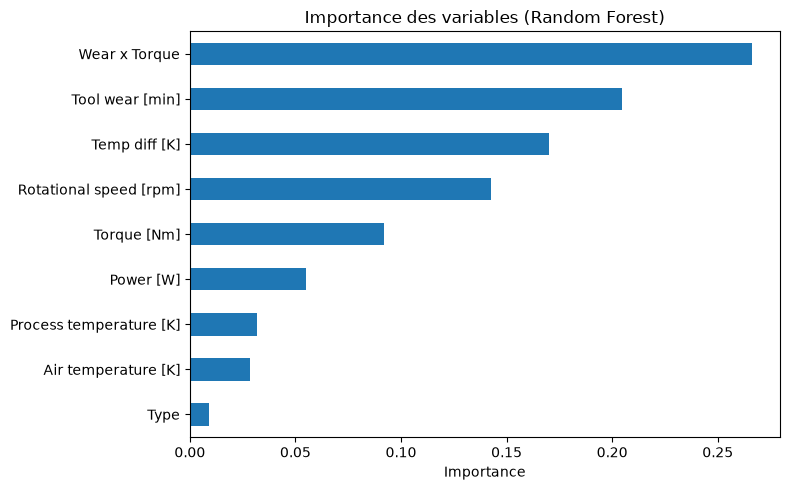

In [11]:
import matplotlib.pyplot as plt

importances = pd.Series(rf_final.feature_importances_, index=X_train.columns).sort_values()

importances.plot(kind='barh', figsize=(8, 5))
plt.title("Importance des variables (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Importance des variables

Le Random Forest s'appuie principalement sur les variables dérivées :
- **Usure × couple** est la variable la plus importante, en lien avec le mode de panne par surcharge (OSF).
- **L'écart de température** (procédé − air) arrive en troisième position, alors que chaque température prise isolément pèse peu : c'est leur différence qui est informative (lien avec la panne HDF).
- L'**usure de l'outil** et la **vitesse de rotation** complètent le haut du classement.
- Le **type de produit** apporte très peu d'information.

Les variables corrélées se partageant l'importance, ce classement indique une tendance et non une hiérarchie stricte.

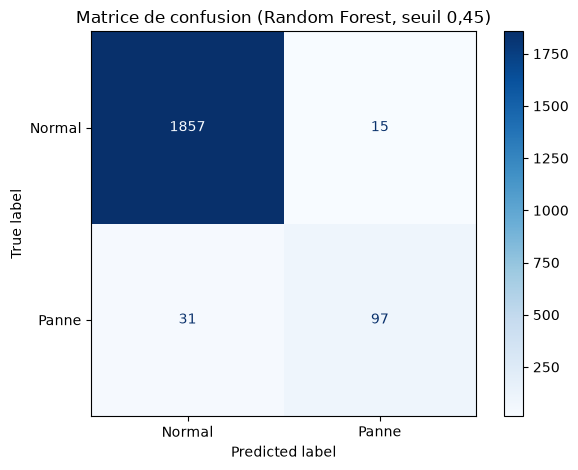

In [12]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

os.makedirs("images", exist_ok=True)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_final,
    display_labels=['Normal', 'Panne'],
    cmap='Blues'
)
plt.title("Matrice de confusion (Random Forest, seuil 0,45)")
plt.tight_layout()
plt.savefig("images/importance_variables.png", dpi=150)
plt.savefig("images/matrice_confusion.png", dpi=150)
plt.show()